In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   Дата          301355 non-null  object
 1   Склад         301355 non-null  int64 
 2   Контрагент    301355 non-null  object
 3   Номенклатура  301355 non-null  object
 4   Количество    301355 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.5+ MB
None


Проверяем формат столбцов

In [4]:
# Переводим столбец "Дата" в datetime
df['Дата'] = pd.to_datetime(df['Дата'])


In [5]:
# Проверим результат
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Дата          301355 non-null  datetime64[ns]
 1   Склад         301355 non-null  int64         
 2   Контрагент    301355 non-null  object        
 3   Номенклатура  301355 non-null  object        
 4   Количество    301355 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.5+ MB
None


Сразу переведем столбец "Дата" в правильный формат

Сгруппируйте данные по дате, посчитайте количество продаж

In [6]:
grouped_df = (
    df.groupby('Дата', as_index=False)['Количество'].sum()
)

print(grouped_df.head())


        Дата  Количество
0 2018-01-04        3734
1 2018-01-05        3643
2 2018-01-06        3193
3 2018-01-07        3298
4 2018-01-09        4055


Вывести несколько первых строк сгруппированных данных

In [7]:
print(grouped_df.head(10))

        Дата  Количество
0 2018-01-04        3734
1 2018-01-05        3643
2 2018-01-06        3193
3 2018-01-07        3298
4 2018-01-09        4055
5 2018-01-10        3653
6 2018-01-11        3176
7 2018-01-12        3092
8 2018-01-13        3294
9 2018-01-14        3228


Нарисуйте график продаж у `grouped_df`

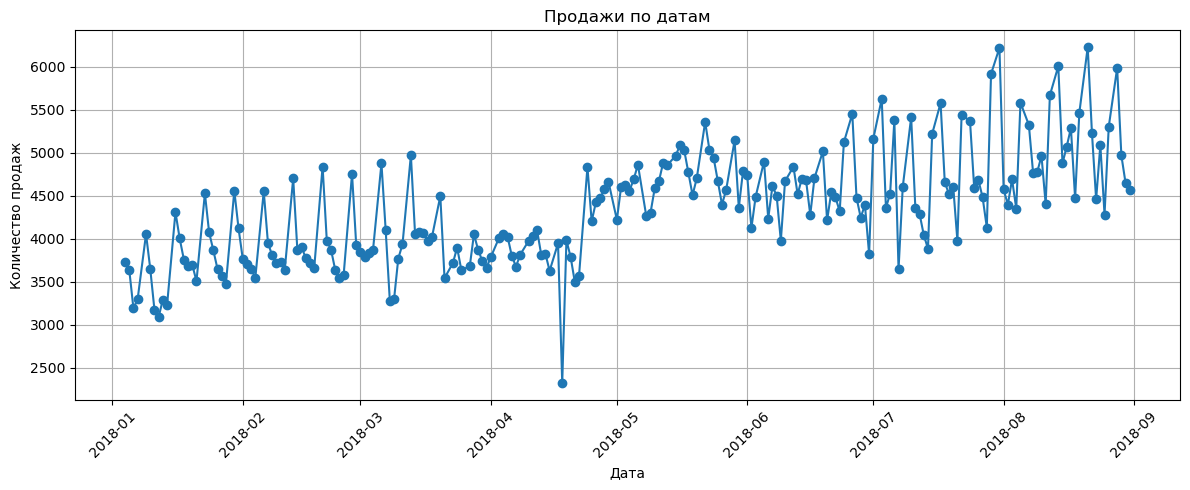

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    grouped_df['Дата'],
    grouped_df['Количество'],
    marker='o'
)

plt.title('Продажи по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
На графике показана динамика продаж по датам за период примерно с января по конец августа 2018 года. Ось X — дата, ось Y — общее количество проданных единиц за день.

1️⃣ Общий тренд
Наблюдается устойчивый восходящий тренд.
В начале периода (январь) продажи находятся в диапазоне ≈ 3200–3800.
К концу периода (август) уровень продаж увеличивается до ≈ 4500–6200.
Это говорит о росте объёма продаж со временем.

2️⃣ Сезонность и регулярные колебания
Хорошо заметны периодические колебания с примерно одинаковым интервалом.
Характер колебаний напоминает недельную сезонность:
регулярные пики (вероятно, будние дни),
регулярные провалы (возможные выходные или дни с низкой активностью).
Амплитуда колебаний со временем увеличивается:
в начале года ≈ 400–600,
ближе к лету и августу ≈ 800–1200.

3️⃣ Аномалии и выбросы
В середине апреля наблюдается резкий одиночный провал продаж:
значение падает примерно до ≈ 2300, что сильно выбивается из соседних дней.
Это может быть:
выходной/праздничный день,
сбой в данных,
логистическая проблема,
отсутствие продаж по складам.

Также встречаются отдельные локальные пики (особенно в июле–августе) выше 6000, которые могут соответствовать акциям или пиковому спросу. 
4️⃣ Изменение уровня продаж по периодам
Январь – март
Продажи стабильны, умеренные.
Средний уровень: ≈ 3600–4000.
Колебания относительно небольшие.

Апрель
Небольшое замедление роста.
Присутствует сильный выброс вниз.
После провала продажи быстро возвращаются к нормальному уровню.

Май – июнь
Чёткий рост.
Средний уровень поднимается до ≈ 4500–5000.
Колебания становятся более выраженными.

Июль – август
Максимальные значения за весь период.
Средний уровень ≈ 4800–5500.
Частые пики выше 6000.
Самая высокая волатильность.

5️⃣ Волатильность
Со временем увеличивается разброс значений.
Это может говорить:
о росте бизнеса,
об увеличении количества клиентов,
о расширении ассортимента или складов.

6️⃣ Качество данных
В целом данные выглядят реалистично и последовательно.
Есть минимум один явный выброс, который стоит дополнительно проверить.
Нет длинных периодов отсутствия данных.

7️⃣ Выводы
Продажи растут со временем.
Присутствует выраженная регулярная сезонность.
Есть аномальные дни, требующие анализа.
Бизнес находится в фазе роста, но с увеличивающейся вариативностью спроса.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [10]:
from scipy.stats import zscore

df['z_score'] = zscore(df['Количество'])


In [11]:
outlier_row = df.loc[df['z_score'].abs().idxmax()]
outlier_row


print("Строка с максимальным выбросом:")
print(outlier_row)


Строка с максимальным выбросом:
Дата            2018-06-28 00:00:00
Склад                             1
Контрагент              address_208
Номенклатура              product_0
Количество                      200
z_score                   65.723369
Name: 218822, dtype: object


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [12]:
df['День_недели'] = df['Дата'].dt.dayofweek  # понедельник=0
df['Месяц'] = df['Дата'].dt.month


In [13]:
filtered_df = df[
    (df['Склад'] == 3) &
    (df['День_недели'] == 2) &
    (df['Месяц'].isin([6, 7, 8]))
]

In [14]:
product_sales = (
    filtered_df
    .groupby('Номенклатура', as_index=False)['Количество']
    .sum()
)

In [15]:
top_product = product_sales.loc[
    product_sales['Количество'].idxmax()
]

top_product

Номенклатура    product_1
Количество           2267
Name: 1, dtype: object

Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [136]:
weather = pd.read_csv(
    'weather_astana.csv',
    sep=';',          
    skiprows=6,       # описание
    decimal=',',      
    encoding='cp1251'
)

In [137]:
print(weather.head())


  Местное время в Астане     T     Po      P   Pa     U  \
0       31.08.2018 23:00   8.2  736.6  768.3  0.2  78.0   
1       31.08.2018 20:00   9.6  736.4  767.9  1.2  88.0   
2       31.08.2018 17:00  11.3  735.2  766.4  0.4  83.0   
3       31.08.2018 14:00  12.3  734.8  765.9  0.9  80.0   
4       31.08.2018 11:00  13.2  733.9  764.8  1.0  83.0   

                                       DD  Ff  ff10  ff3  ...  \
0          Ветер, дующий с северо-востока   4   NaN  NaN  ...   
1    Ветер, дующий с западо-северо-запада   3   NaN  NaN  ...   
2  Ветер, дующий с востоко-северо-востока   4   NaN  NaN  ...   
3          Ветер, дующий с северо-востока   4   NaN  NaN  ...   
4   Ветер, дующий с северо-северо-востока   4   NaN  NaN  ...   

                                                  Cm  \
0  Высококучевых, высокослоистых или слоисто-дожд...   
1  Высококучевых, высокослоистых или слоисто-дожд...   
2                                                NaN   
3                             

In [138]:
print(weather.dtypes)


Местное время в Астане     object
T                         float64
Po                        float64
P                         float64
Pa                        float64
U                         float64
DD                         object
Ff                          int64
ff10                      float64
ff3                       float64
N                          object
WW                         object
W1                         object
W2                         object
Tn                        float64
Tx                        float64
Cl                         object
Nh                         object
H                          object
Cm                         object
Ch                         object
VV                        float64
Td                        float64
RRR                        object
tR                        float64
E                          object
Tg                        float64
E'                         object
sss                        object
dtype: object


In [139]:
# Преобразуем столбец в datetime
weather['Местное время в Астане'] = pd.to_datetime(weather['Местное время в Астане'], format='%d.%m.%Y %H:%M')

# Создадим отдельный столбец с датой (без времени)
weather['Дата'] = weather['Местное время в Астане'].dt.date


In [140]:
# Группируем по дате и берём среднюю температуру
daily_temp = weather.groupby('Дата')['T'].mean().reset_index()
daily_temp.rename(columns={'T': 'Средняя_температура'}, inplace=True)

print(daily_temp.head())


         Дата  Средняя_температура
0  2018-01-01              -9.4625
1  2018-01-02              -9.5125
2  2018-01-03             -11.4625
3  2018-01-04             -14.0750
4  2018-01-05             -16.8625


In [141]:
grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата']).dt.date

# Объединяем
merged_df = pd.merge(grouped_df, daily_temp, on='Дата', how='left')

print(merged_df.head())


         Дата  Количество  Средняя_температура
0  2018-01-04        3734             -14.0750
1  2018-01-05        3643             -16.8625
2  2018-01-06        3193             -13.3000
3  2018-01-07        3298             -12.7500
4  2018-01-09        4055              -6.2500


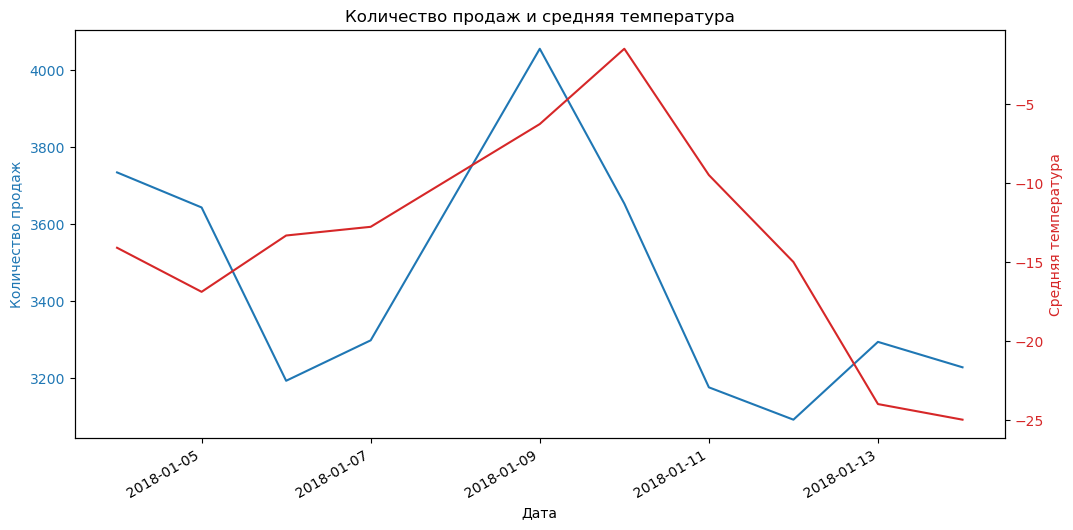

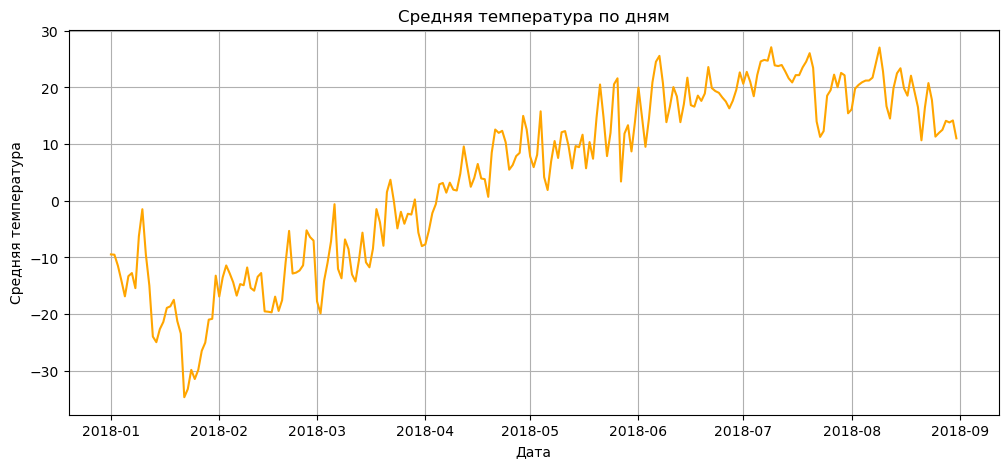

In [143]:
# 4.1 Продажи и температура на одном графике
fig, ax1 = plt.subplots(figsize=(12,6))

color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color=color)
ax1.plot(merged_df['Дата'], merged_df['Количество'], color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # вторичная ось для температуры
color = 'tab:red'
ax2.set_ylabel('Средняя температура', color=color)
ax2.plot(merged_df['Дата'], merged_df['Средняя_температура'], color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Количество продаж и средняя температура')
fig.autofmt_xdate()
plt.show()

# 4.2 Только температура
plt.figure(figsize=(12,5))
plt.plot(daily_temp['Дата'], daily_temp['Средняя_температура'], color='orange')
plt.xlabel('Дата')
plt.ylabel('Средняя температура')
plt.title('Средняя температура по дням')
plt.grid(True)
plt.show()